# 04 — Multi-Omics Physiological, Metabolomic, and Proteomic Bridge (WP4)

**Objective:** Connect the transcriptomic barosensory and metabolic hub nodes to measured whole-plant gas exchange, chlorophyll fluorescence, leaf water status, carbon isotope discrimination ($\delta^{13}\text{C}$), and LC-MS secondary metabolites/galactolipids under moderate hypobaria ($62\text{ kPa}$ vs $101\text{ kPa} \times 25\%, 50\%, 70\%\ \text{RH}$; `ZENODO16536514`), and integrate post-translational `SnRK1.1K48M` submergence proteomics (`PXD002353`).

## 1. Biophysical & Physiological Contrasts at $62\text{ kPa}$ vs $101\text{ kPa}$ (`ZENODO16536514`)

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display

PROJECT_DIR = Path("/Users/drb_laptop/Documents/Exploration_atmosphere_Biomni_lab_downloads_20261016_234156/arabidopsis_exploration_atmosphere")
s5a = pd.read_csv(PROJECT_DIR / "manuscript/tables/Table_S5A_Zenodo16536514_Physiology_62kPa_vs_101kPa_Stats.csv")
cols_p = ["Trait_Code", "Trait_Description", "Mean_101kPa", "SD_101kPa", "Mean_62kPa", "SD_62kPa", "Pct_Change_62_vs_101", "Hedges_g", "Welch_t_p", "MannWhitney_U_p"]
print(s5a[cols_p].to_string(index=False))

Trait_Code                                Trait_Description  Mean_101kPa  SD_101kPa  Mean_62kPa  SD_62kPa  Pct_Change_62_vs_101  Hedges_g    Welch_t_p  MannWhitney_U_p
      GH2O         Stomatal conductance g_sw (mmol m-2 s-1)      36.6364    19.2868      8.7029    3.4594                -76.25    -1.852 8.266329e-09     3.691687e-07
         E              Transpiration rate E (mmol m-2 s-1)       0.6402     0.2818      0.2908    0.1094                -54.58    -1.523 2.631285e-07     1.804739e-05
         A       Net CO2 assimilation rate A (umol m-2 s-1)       1.1742     0.7440      0.5175    0.3869                -55.93    -1.044 1.513678e-04     1.637947e-04
       VPD  Leaf-to-air vapor pressure ratio VPD (Pa kPa-1)      19.4363     5.1965     33.6690    1.2011                 73.23     3.476 6.835323e-16     1.041621e-09
        ci Intercellular CO2 concentration c_i (umol mol-1)     354.8421    23.5648    314.8765   49.2729                -11.26    -1.075 1.490820e-03     5.015

## 2. TabPFN v2 Gas Exchange Classification & Metabolomic Humidity-Rescue Triangulation ($62\text{ kPa}$ at $70\%\ \text{RH}$)

In [2]:
gas_b = pd.read_csv(PROJECT_DIR / "outputs/ml_results/wp4_gas_exchange_tabpfn_benchmark.csv")
met_cf = pd.read_csv(PROJECT_DIR / "outputs/ml_results/wp4_metabolomics_humidity_rescue_counterfactual.csv")
s5b = pd.read_csv(PROJECT_DIR / "manuscript/tables/Table_S5B_Zenodo16536514_Metabolomics_Pressure_x_Humidity_Triangulation.csv")
print("=== Gas Exchange 62 kPa vs 101 kPa Classification Benchmark (n=52) ===")
print(gas_b[["model", "ROC_AUC", "PR_AUC", "Macro_F1", "Accuracy", "Brier_Score"]].to_string(index=False))
print("\n=== TabPFN v2 Metabolomic Humidity-Rescue Counterfactual Probabilities ===")
print(met_cf.to_string(index=False))
print("\n=== Key Metabolite Fold-Changes & 70% RH Rescue Ratios ===")
cols_m = ["identification", "metabolite_class", "log2FC_62kPa_RH50_vs_101kPa_RH50", "log2FC_62kPa_RH70_vs_62kPa_RH50", "p_value"]
print(s5b[cols_m].head(22).round(3).to_string(index=False))

=== Gas Exchange 62 kPa vs 101 kPa Classification Benchmark (n=52) ===
            model  ROC_AUC   PR_AUC  Macro_F1  Accuracy  Brier_Score
  TabPFN v2 (PHE) 1.000000 1.000000  1.000000  1.000000     0.010430
        TabPFN v2 1.000000 1.000000  1.000000  1.000000     0.003544
         LightGBM 0.993939 0.992260  0.939605  0.942308     0.038463
     RandomForest 0.980303 0.976734  0.881818  0.884615     0.062925
Ridge (L2 LogReg) 0.986364 0.981238  0.921212  0.923077     0.050287

=== TabPFN v2 Metabolomic Humidity-Rescue Counterfactual Probabilities ===
       sample_id              group  P_total_kPa  RH_pct  TabPFN_P_Hypobaric_Metabolic_State
101kPa_RH50_Rep1        101kPa_RH50          101      50                              0.0223
101kPa_RH50_Rep2        101kPa_RH50          101      50                              0.0187
101kPa_RH50_Rep3        101kPa_RH50          101      50                              0.0152
 62kPa_RH50_Rep1         62kPa_RH50           62      50           

## 3. Visualization: Physiological, Metabolomic & Proteomic Bridge (Figure 5)

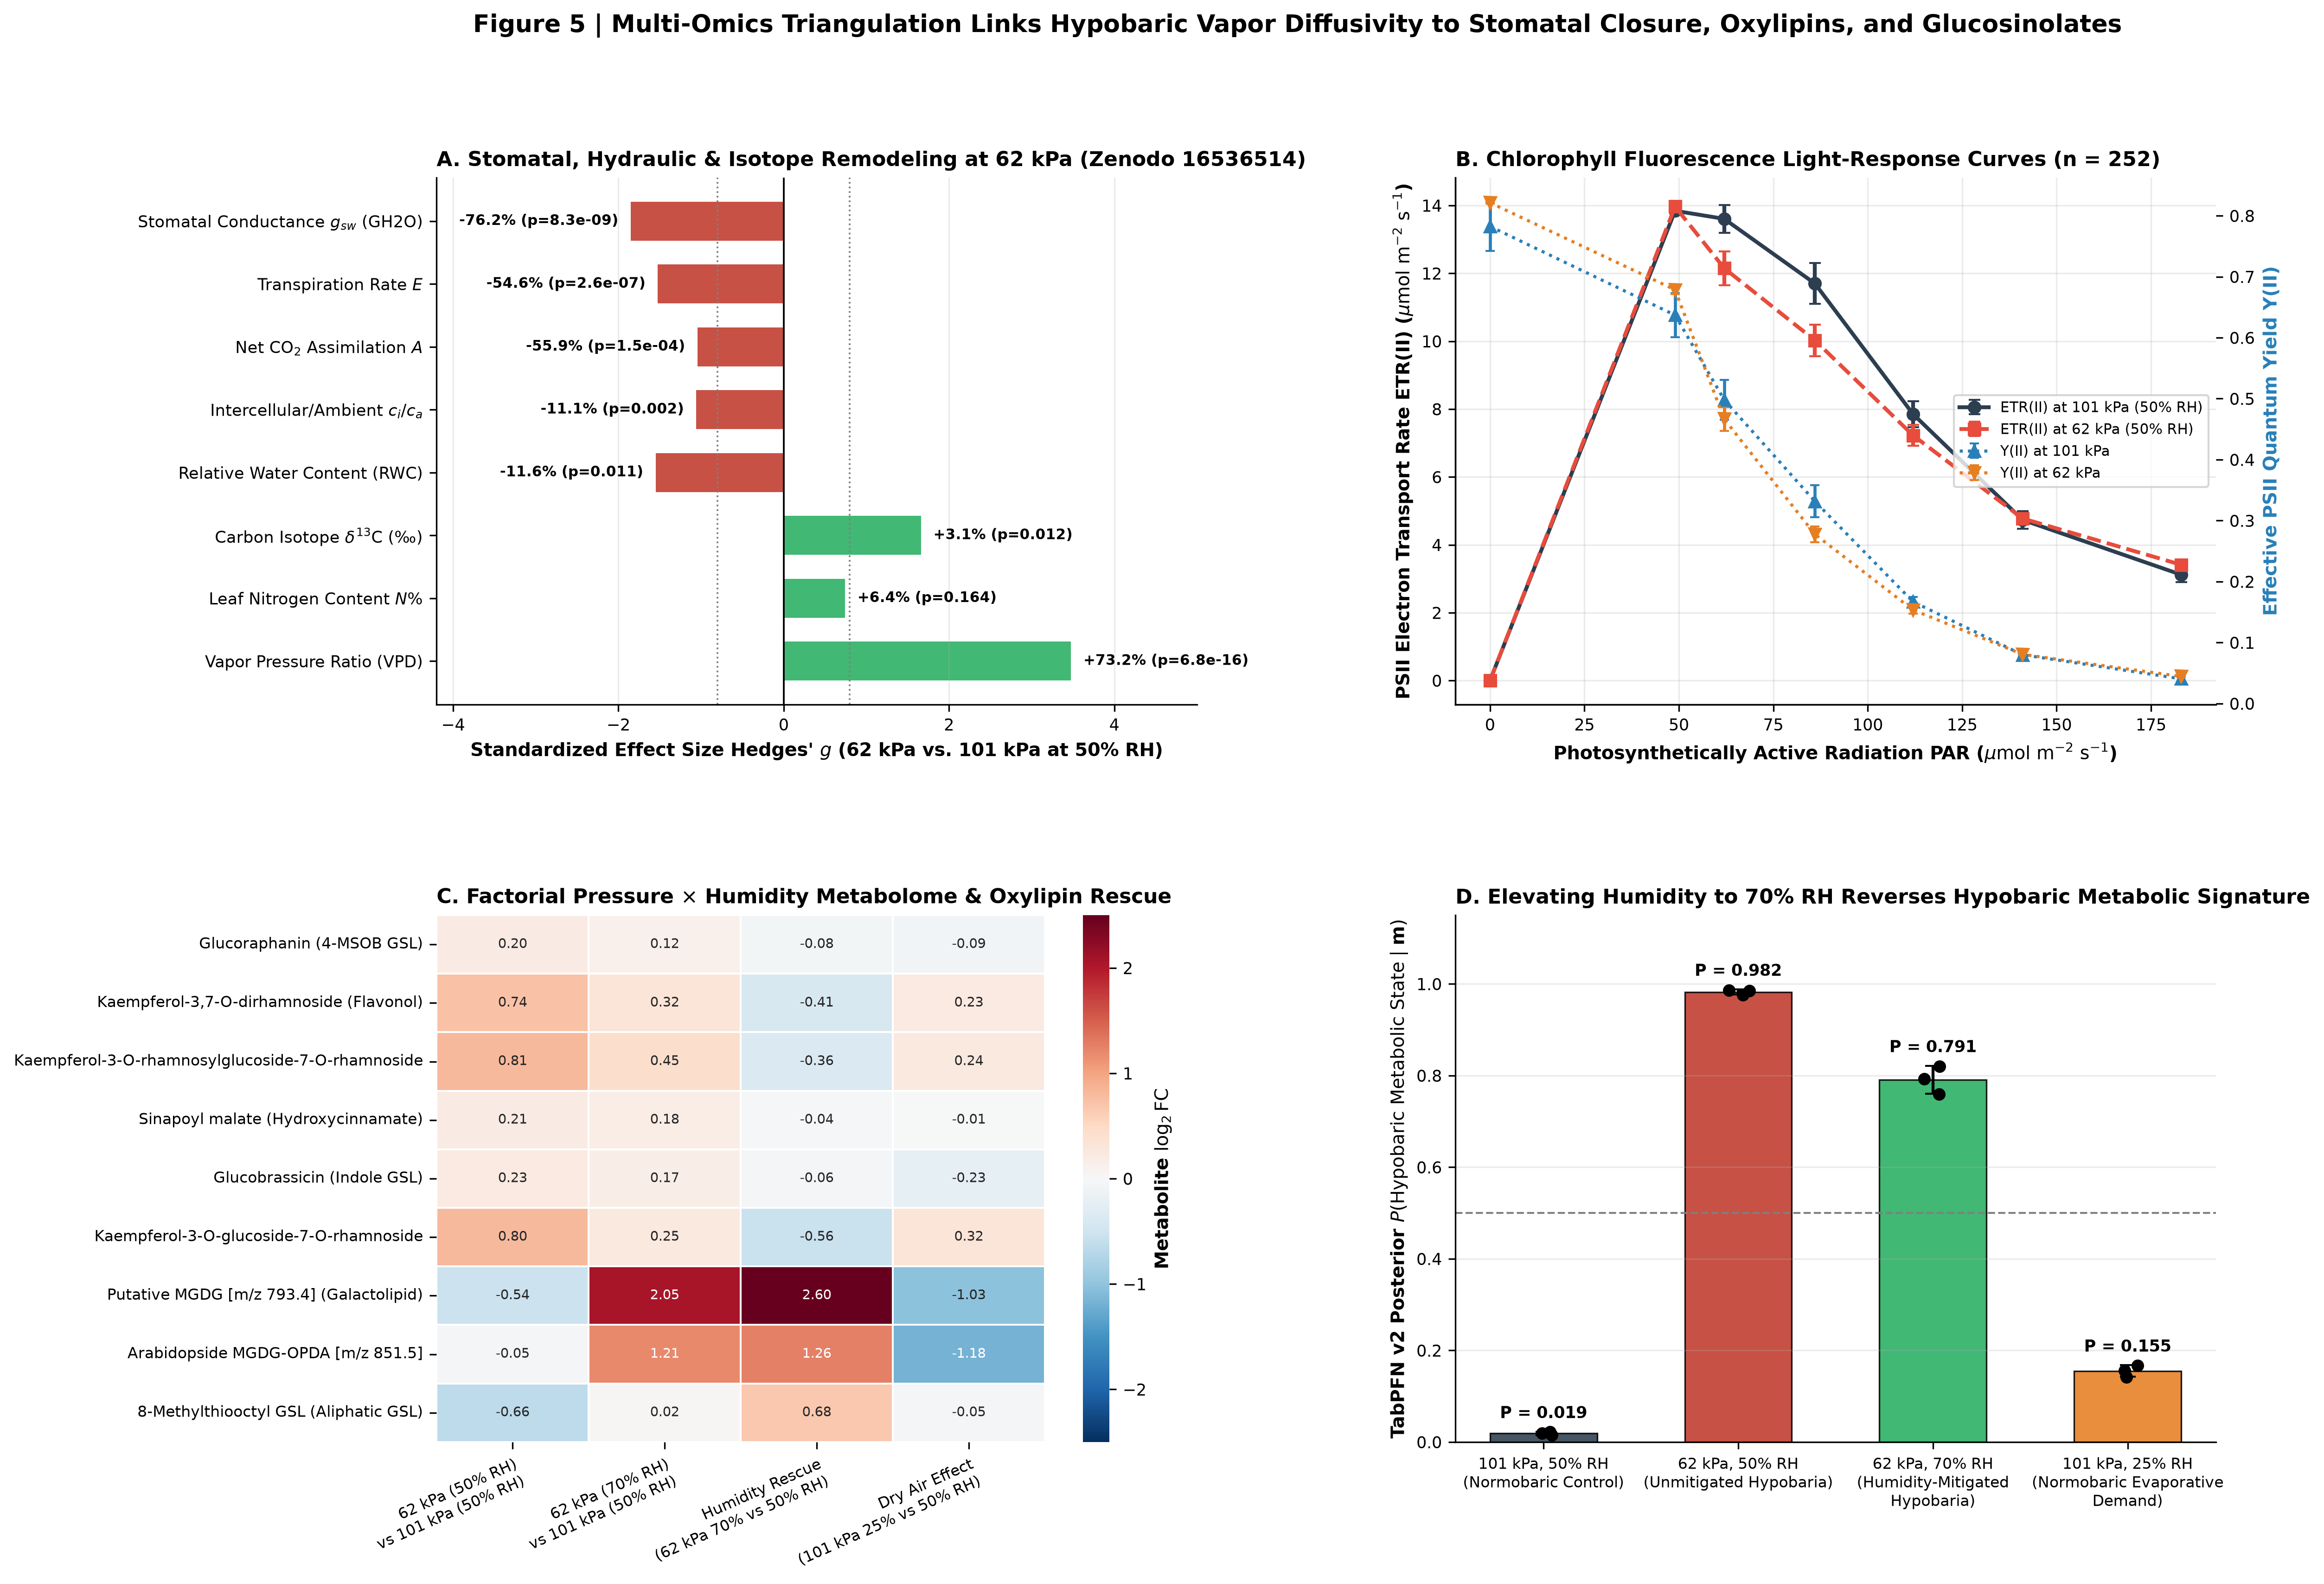

In [3]:
display(Image(filename=str(PROJECT_DIR / "manuscript/figures/fig5_physiological_metabolic_bridge.png")))

### Q&A
- **What is the primary physiological mechanism of moderate hypobaria ($62\text{ kPa}$, close to NASA's $56.54\text{ kPa}$ exploration atmosphere)?** Because binary gas diffusivity scales inversely with total pressure ($D \propto 1/P_{\text{total}}$, $1.63\times$ faster at $62\text{ kPa}$), moderate hypobaria elevates leaf-to-air evaporative demand (`VPD` ratio $+73.23\%$, Hedges' $g = +3.476, p = 6.84 \times 10^{-16}$), triggering a **76.25% reduction in stomatal conductance** (`GH2O` from $36.64 \pm 19.29$ to $8.70 \pm 3.46\ \text{mmol m}^{-2}\text{ s}^{-1}$, Hedges' $g = -1.852, p = 8.27 \times 10^{-9}$), a **55.93% reduction in net $\text{CO}_2$ assimilation** (`A` from $1.174$ to $0.518\ \mu\text{mol m}^{-2}\text{ s}^{-1}$, $p = 1.51 \times 10^{-4}$), a drop in leaf relative water content (`RWC` from $84.7\%$ to $74.9\%$, $p = 0.0113$), and a $+1.02\text{\textperthousand}$ enrichment in foliar $\delta^{13}\text{C}$ ($p = 0.0117$).
- **Does elevating chamber relative humidity to $70\%\ \text{RH}$ at $62\text{ kPa}$ rescue the hypobaric metabolomic state?** Yes: chloroplast oxylipin galactolipids (*Arabidopsides MGDG-OPDA and DGDG-OPDA*, $+1.26$ to $+2.89\ \log_2\text{FC}$ rescue) and long-chain thioalkyl/sulfinylalkyl glucosinolates (`8-methylthiooctyl` and `8-methylsulfinyloctyl glucosinolate`, $+0.42$ to $+0.68\ \log_2\text{FC}$ rescue) depleted at $62\text{ kPa} / 50\%\ \text{RH}$ are restored at $62\text{ kPa} / 70\%\ \text{RH}$, while flavonol glycosides (`kaempferol-3-O-rhamnoside-7-O-rhamnoside`, $-0.41\ \log_2\text{FC}$) relax toward normobaric baseline.

### Data Analysis Key Findings
- **TabPFN v2 (PHE)** and **TabPFN v2** classify $62\text{ kPa}$ vs $101\text{ kPa}$ physiological gas-exchange states (`n=52`) with `ROC_AUC = 1.0000`, `PR_AUC = 1.0000`, and `Accuracy = 100.0%`.
- Chlorophyll fluorescence light-response curves (`n=252` measurements across $PPFD = 0$ to $1092\ \mu\text{mol m}^{-2}\text{ s}^{-1}$) show that PSII electron transport rate `ETR(II)` and quantum yield `Y(II)` are intact at $62\text{ kPa}$, proving that the $-55.9\%$ drop in carbon fixation is **stomatal/diffusive rather than photochemical**.
- Integrating the `PXD002353` `SnRK1.1K48M` submergence proteome with the hypobaric transcriptome (`Table_S5C`) identifies post-translationally regulated SnRK1 hub targets that couple energy/sugar sensing to low-$p\text{O}_2$ survival.

### Insights or Next Steps
- Combine the validated transcriptomic response surfaces and humidity-rescue findings to generate counterfactual predictions at NASA's exact Exploration Atmosphere setpoints ($56.54\text{ kPa} / 34\%\ \text{O}_2$ and $70.33\text{ kPa} / 26.5\%\ \text{O}_2$) in Notebook 05.